# 01 · Embeddings and cosine similarity

Companion notebook for *Questioning the mathematical foundations of AI*, Dr Ana Rojo-Echeburúa, PyCon España 2026.

## What this notebook does

Pretty much every retrieval system you've used in the last few years (RAG pipelines, semantic search, "chat with your documents") does the same thing under the hood. It turns each piece of text into a long list of numbers, and when you ask a question it turns your question into a list of numbers too. Then it returns the texts whose lists point in the most similar direction to yours. That "most similar direction" is called cosine similarity, and it's measured in ordinary flat space, the same geometry you learnt at school.

In this notebook we take that pipeline apart one step at a time, with code that runs on a laptop. By the end you'll know exactly what the similarity score computes, and you'll have seen two places where it hands you a number you shouldn't trust.

## The steps

1. **What an embedding is.** One sentence in, 384 numbers out.
2. **Static and contextual embeddings.** A short history of how we got here.
3. **Seeing embeddings in 2D.** Twelve sentences on a scatter plot.
4. **Cosine similarity.** The formula, by hand and with scikit-learn.
5. **Three metrics, one ranking.** Dot product, cosine and distance turn out to be the same thing.
6. **The retrieval pipeline in a few lines.** A tiny search engine.
7. **Hybrid search.** Keyword search, embedding search and how to combine them.
8. **Where it breaks: the scores bunch up.** Why "above 0.8 means relevant" is a trap.
9. **Where it breaks: cosine goes both ways.** One-way relationships and arbitrary scores.
10. **Takeaway.**

## Setup

First the imports, a fixed random seed (0, everywhere, so your numbers match mine) and a plot style that matches the slides from the talk.

In [1]:
import os
import random
import re
import warnings
import logging

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
import torch

warnings.filterwarnings("ignore")
logging.getLogger("sentence_transformers").setLevel(logging.ERROR)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Colours from the talk slides
BG, TEXT = "#CFD5D3", "#030303"
BROWN, DARK_BROWN, SLATE, LIGHT_GREY = "#7F584A", "#4F3733", "#767F87", "#A9B0B4"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": TEXT, "axes.edgecolor": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "figure.dpi": 110,
})
print("Ready.")

Ready.


**What you're seeing:** nothing exciting yet. If it prints `Ready.` without errors, every library is installed and you're good to go.

## Step 1 · What an embedding is

An embedding turns a piece of text into a vector, which is just a list of numbers. If the list has $n$ numbers, you can think of it as a point (or an arrow starting at the origin) in an $n$-dimensional space, written $\mathbb{R}^n$.

The embedding model learns where to put each text so that relationships in meaning show up as relationships in geometry. Two sentences about late invoices should land close together, and a sentence about paella should land somewhere else entirely.

$n$ is the number of values in the vector, and each model fixes its own:

| Model | $n$ | Source |
|---|---|---|
| all-MiniLM-L6-v2 | 384 | Reimers & Gurevych, Sentence-Transformers model card (2021) |
| BERT-base and many open retrieval models | 768 | Devlin et al., NAACL 2019 |
| OpenAI text-embedding-3-large | 3,072 | OpenAI, *New embedding models and API updates* (January 2024) |

We'll use all-MiniLM-L6-v2 for the whole notebook because it's small, fast and happy on a CPU. Let's give it one sentence and look at what comes back.

In [2]:
model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")

v = model.encode("The supplier still hasn't paid the March invoice.")

print("shape:          ", v.shape)
print("first 8 values: ", np.round(v[:8], 4))
print("length ||v||:   ", round(float(np.linalg.norm(v)), 6))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

shape:           (384,)
first 8 values:  [-0.0221  0.036   0.0839 -0.0446 -0.0056 -0.0207 -0.1339 -0.029 ]
length ||v||:    1.0


**What you're seeing:** one sentence became 384 numbers. None of them means anything on its own (there's no "invoice" dimension you can point at), and all the meaning is in where the whole vector points compared with other vectors. The length comes out as exactly 1.0 because all-MiniLM-L6-v2 normalises its output, and that detail matters in Step 5.

## Step 2 · Static and contextual embeddings

The first embeddings that really took off gave every word exactly one vector. word2vec (Mikolov et al., arXiv 2013) and GloVe (Pennington, Socher & Manning, EMNLP 2014) work like a dictionary, so "bank" gets one vector and the river bank has to share it with the bank that holds your savings. Contextual models fixed that. ELMo (Peters et al., NAACL 2018) and BERT (Devlin et al., NAACL 2019, first released in 2018) give a word a vector that depends on the sentence around it.

Retrieval needs something slightly different again, because you want one vector for a whole chunk of text. That's what sentence embeddings give you, starting with Sentence-BERT (Reimers & Gurevych, EMNLP 2019). The models people use for retrieval today are in this family: multilingual-e5-large, bge-m3, text-embedding-3-large, gemini-embedding-001 and Qwen3-Embedding-8B, for example.

If you like placing things on the AI family tree, embedding models are deep learning and sit just outside generative AI (they output vectors and generate no text). Older methods like GloVe and LSA are matrix factorisations, which puts them in classic machine learning.

## Step 3 · Seeing embeddings in 2D

Now twelve short sentences, four on each of three topics: late invoices, football and recipes. We embed all of them, and because nobody can look at 384 dimensions we project them down to two with PCA (principal component analysis). PCA finds the two directions along which the points are most spread out and flattens everything onto those.

One warning before you look. A 2D picture of embeddings is always a projection, a bit like the shadow a 3D object casts on a wall. Points that look close in the shadow can be far apart in the full space, and most of the information is lost on the way down. It's great for intuition and terrible for measuring anything.

Share of the variance kept by the 2D picture: 0.413


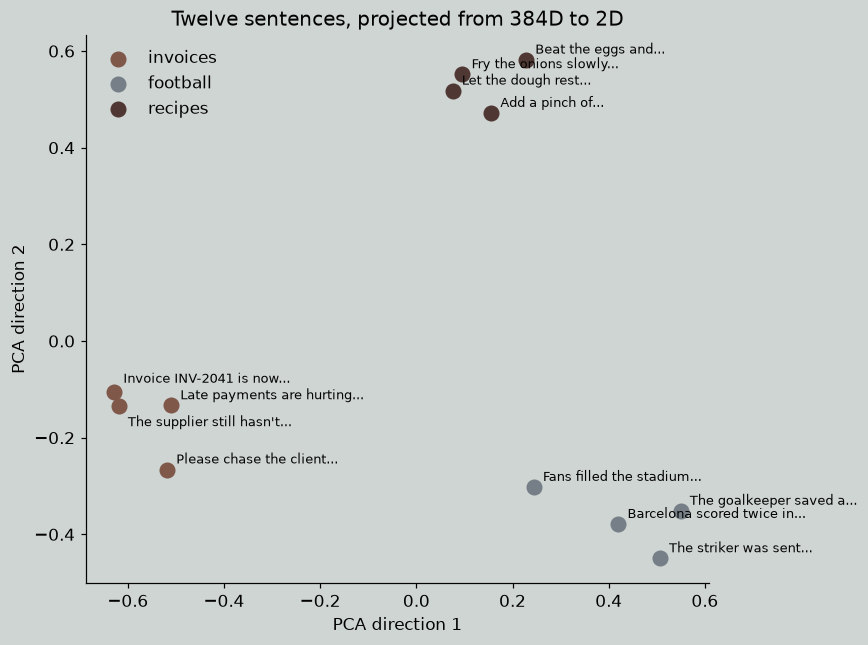

In [3]:
sentences = [
    # late invoices
    "The supplier still hasn't paid the March invoice.",
    "Invoice INV-2041 is now 60 days overdue.",
    "Please chase the client about the unpaid bill.",
    "Late payments are hurting our cash flow this quarter.",
    # football
    "Barcelona scored twice in the second half.",
    "The goalkeeper saved a penalty in extra time.",
    "The striker was sent off after a reckless tackle.",
    "Fans filled the stadium for the derby.",
    # recipes
    "Fry the onions slowly until they turn golden.",
    "Add a pinch of saffron to the paella rice.",
    "Beat the eggs and fold in the potatoes for the tortilla.",
    "Let the dough rest for an hour before baking.",
]
topics = ["invoices"] * 4 + ["football"] * 4 + ["recipes"] * 4
topic_colour = {"invoices": BROWN, "football": SLATE, "recipes": DARK_BROWN}

E = model.encode(sentences, normalize_embeddings=True)   # shape (12, 384)

pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(E)
print("Share of the variance kept by the 2D picture:", round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(figsize=(8, 6))
for t in topic_colour:
    idx = [i for i, x in enumerate(topics) if x == t]
    ax.scatter(P[idx, 0], P[idx, 1], s=90, color=topic_colour[t], label=t)
offsets = {0: (6, -13), 1: (6, 6)}   # nudge two labels that would overlap
for i, s in enumerate(sentences):
    short = " ".join(s.split()[:4]) + "..."
    ax.annotate(short, P[i], xytext=offsets.get(i, (6, 4)), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("PCA direction 1")
ax.set_ylabel("PCA direction 2")
ax.set_title("Twelve sentences, projected from 384D to 2D")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**What you're seeing:** the invoice, football and recipe sentences fall into three separate groups, and nobody gave the model those topic labels. The picture keeps only 41% of the variance (the 0.413 above), so more than half of what separates these vectors is invisible here. Use pictures like this to build intuition and do your measuring in the full 384 dimensions.

## Step 4 · Cosine similarity

Cosine similarity measures the angle between two vectors and ignores how long they are:

$$\cos\theta = \frac{u \cdot v}{\lVert u \rVert \, \lVert v \rVert}$$

$u \cdot v$ is the dot product (multiply matching entries and add them all up) and $\lVert u \rVert$ is the length of $u$. You get 1 when the vectors point the same way, 0 when they're at right angles and −1 when they point in opposite directions.

Why throw the length away? The assumption is that direction carries the meaning and length is mostly noise from things like how long the sentence was. Keep that assumption in your back pocket, because it comes back to bite in Step 9.

Here it is by hand with numpy, checked against scikit-learn.

In [4]:
def cosine(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

pairs = [(0, 1), (0, 4), (4, 5), (9, 10)]
for i, j in pairs:
    mine = cosine(E[i], E[j])
    sk = cosine_similarity(E[i:i+1], E[j:j+1])[0, 0]
    print(f"{mine:6.3f}  (sklearn {sk:6.3f})   {sentences[i][:38]:<40} vs  {sentences[j][:38]}")

 0.589  (sklearn  0.589)   The supplier still hasn't paid the Mar   vs  Invoice INV-2041 is now 60 days overdu
 0.014  (sklearn  0.014)   The supplier still hasn't paid the Mar   vs  Barcelona scored twice in the second h
 0.410  (sklearn  0.410)   Barcelona scored twice in the second h   vs  The goalkeeper saved a penalty in extr
 0.313  (sklearn  0.313)   Add a pinch of saffron to the paella r   vs  Beat the eggs and fold in the potatoes


**What you're seeing:** my hand-written cosine and scikit-learn agree to three decimals, so there's no magic hiding in the library. Two invoice sentences score 0.59, two football sentences 0.41, and an invoice sentence against a football one scores 0.01, which is basically a right angle. The two recipe sentences only reach 0.31, a good reminder that being on the same topic doesn't guarantee a high number.

The same thing for every pair at once gives a 12 × 12 similarity matrix. Each square is the cosine between the sentence in that row and the sentence in that column.

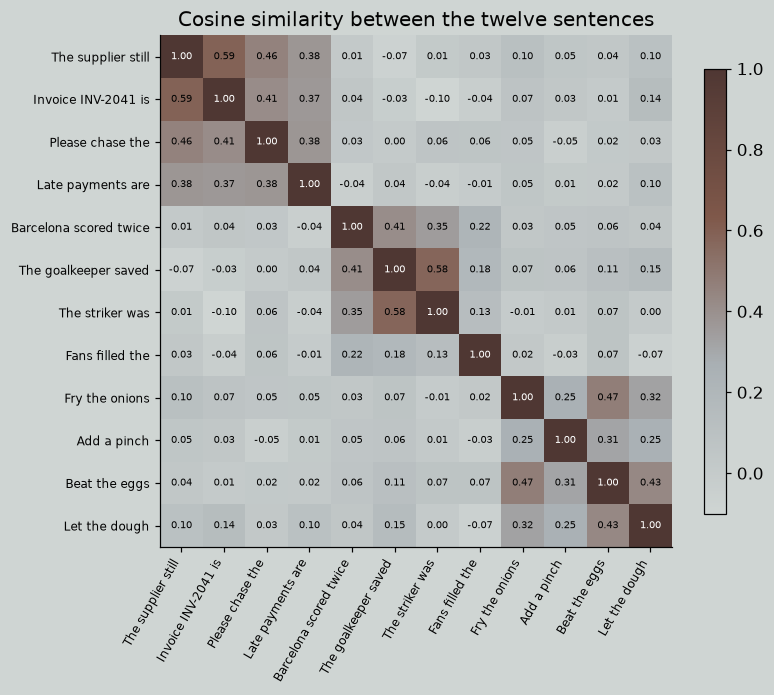

In [5]:
S = cosine_similarity(E)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("deck", [BG, LIGHT_GREY, BROWN, DARK_BROWN])
im = ax.imshow(S, cmap=cmap, vmin=-0.1, vmax=1)
labels = [" ".join(s.split()[:3]) for s in sentences]
ax.set_xticks(range(12)); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(12)); ax.set_yticklabels(labels, fontsize=8)
for i in range(12):
    for j in range(12):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if S[i, j] > 0.6 else TEXT)
ax.set_title("Cosine similarity between the twelve sentences")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**What you're seeing:** the three darker blocks along the diagonal are the three topics, and the diagonal itself is 1.00 because every sentence points exactly the same way as itself. Notice how few squares get anywhere near 1. With this model, 0.6 between two different sentences is already a strong match, which is worth remembering when we get to thresholds in Step 8.

## Step 5 · Three metrics, one ranking

Vector databases usually offer you three ways to compare vectors:

- **Dot product** $u \cdot v$ (bigger means more similar)
- **Cosine similarity** (bigger means more similar)
- **Euclidean distance** $\lVert u - v \rVert$, the straight-line distance (smaller means more similar)

They look like three different ideas, but once every vector has length 1 they collapse into one. With $\lVert u \rVert = \lVert v \rVert = 1$ the dot product *is* the cosine, and expanding the distance gives

$$\lVert u - v \rVert^2 = \lVert u \rVert^2 + \lVert v \rVert^2 - 2\, u \cdot v = 2 - 2\cos\theta .$$

So the distance is just a decreasing function of the cosine, and all three must put documents in exactly the same order. Let's check that with a query against our twelve sentences.

In [6]:
query = "Who still owes us money?"
q = model.encode(query, normalize_embeddings=True)

dot = E @ q
cos = np.array([cosine(e, q) for e in E])
dist = np.linalg.norm(E - q, axis=1)

rank_dot = np.argsort(-dot)
rank_cos = np.argsort(-cos)
rank_dist = np.argsort(dist)

print("Query:", query, "\n")
print(f"{'rank':<5}{'dot':>7}{'cosine':>8}{'dist':>7}   sentence")
for r, i in enumerate(rank_cos[:5], 1):
    print(f"{r:<5}{dot[i]:7.3f}{cos[i]:8.3f}{dist[i]:7.3f}   {sentences[i]}")

print("\nSame ranking from all three?", (rank_dot == rank_cos).all() and (rank_cos == rank_dist).all())
print("Largest error in ||u-v||^2 = 2 - 2cos:", f"{np.abs(dist**2 - (2 - 2 * cos)).max():.1e}")

Query: Who still owes us money? 

rank     dot  cosine   dist   sentence
1      0.420   0.420  1.077   Please chase the client about the unpaid bill.
2      0.380   0.380  1.114   The supplier still hasn't paid the March invoice.
3      0.362   0.362  1.129   Late payments are hurting our cash flow this quarter.
4      0.267   0.267  1.211   Invoice INV-2041 is now 60 days overdue.
5      0.075   0.075  1.360   Beat the eggs and fold in the potatoes for the tortilla.

Same ranking from all three? True
Largest error in ||u-v||^2 = 2 - 2cos: 5.8e-07


**What you're seeing:** dot product and cosine give identical numbers (they're the same thing once every length is 1), the distance column runs the other way, and all three put the sentences in the same order. The identity $\lVert u - v \rVert^2 = 2 - 2\cos\theta$ holds up to about $6 \times 10^{-7}$, which is just float32 rounding. And the four invoice sentences come out on top for a question that shares almost none of their words, which is dense retrieval doing exactly its job.

## Step 6 · The retrieval pipeline in a few lines

That's honestly most of a dense retrieval system. The recipe goes like this:

1. Split your documents into chunks.
2. Embed every chunk once, normalised to length 1, and store the vectors.
3. When a question arrives, embed it into **the same space**.
4. Compute `scores = docs @ q` (one dot product per chunk, which is the cosine because everything has length 1).
5. Sort and keep the top $k$.

"The same space" usually means the same model. Some systems use a separate query encoder trained jointly with the document encoder, like DPR (Karpukhin et al., EMNLP 2020), and some use one model with a `"query: "` or `"passage: "` prefix in front of the text, like E5 (Wang et al., arXiv 2022). all-MiniLM-L6-v2 needs no prefix.

Here's a small knowledge base for a finance team. It has a few invoices with deliberately similar IDs (you'll see why in Step 7) and a couple of off-topic chunks thrown in.

In [7]:
chunks = [
    "Invoice INV-2041 from Calderwick Ltd was due on 3 September and remains unpaid.",
    "Invoice INV-2014 from Calderwick Ltd is overdue and has been chased twice.",
    "Invoice INV-2401 is unpaid and now 45 days late.",
    "Invoice INV-2042 from Calderwick Ltd was paid in full on 28 August.",
    "Our standard payment terms are 30 days from the invoice date.",
    "If customers settle bills after the due date, we send reminders after 7 days and final notices after 30.",
    "Refunds are processed within five working days of approval.",
    "Expense claims need a receipt and sign-off from your line manager.",
    "Supplier contracts are renewed every January.",
    "Barcelona won the derby 2-1 on Sunday night.",
    "Paella needs short-grain rice and a wide, shallow pan.",
    "The quarterly report breaks revenue down by region.",
]

doc_emb = model.encode(chunks, normalize_embeddings=True)   # step 2: embed once

def dense_search(query, k=3):
    q = model.encode(query, normalize_embeddings=True)       # step 3: same space
    scores = doc_emb @ q                                     # step 4: one dot product per chunk
    top = np.argsort(-scores)[:k]                            # step 5: top k
    return [(float(scores[i]), chunks[i]) for i in top]

for score, chunk in dense_search("Which supplier agreements need renewing?"):
    print(f"{score:.3f}   {chunk}")

0.710   Supplier contracts are renewed every January.
0.306   Our standard payment terms are 30 days from the invoice date.
0.241   If customers settle bills after the due date, we send reminders after 7 days and final notices after 30.


**What you're seeing:** the contracts chunk comes first with 0.71, even though the query says "agreements" and "renewing" and the chunk says "contracts" and "renewed". Then there's a big drop to about 0.3 for everything else, which is what a clear winner looks like. That's the whole trick of dense retrieval, and it fits in about five lines.

## Step 7 · Hybrid search

Embeddings match meaning, and that's their strength and their weakness. Ask about an invoice number and an embedding model sees "some invoice-looking thing", so INV-2041 and INV-2042 end up as near neighbours. For exact strings like IDs, product codes and names, plain keyword search is often better.

The classic keyword ranker is **BM25** (Robertson & Zaragoza, *Foundations and Trends in Information Retrieval*, 2009). It scores a chunk by how often your query words appear in it, gives extra weight to rare words and corrects for chunk length. It treats "customer" and "client" as two unrelated strings, which is exactly why it complements embeddings so well.

To combine the two rankings, most hybrid systems use **Reciprocal Rank Fusion** (Cormack, Clarke & Büttcher, SIGIR 2009):

$$\text{RRF}(d) = \sum_{r} \frac{1}{k + \text{rank}_r(d)}, \qquad k = 60$$

For each document $d$ you add up one small fraction per ranker $r$, and a better rank gives a bigger fraction. RRF only looks at ranks, so you never have to work out how a BM25 score of 4.2 compares with a cosine of 0.61. The $k = 60$ comes from the original paper and damps the influence of any single ranker's top spot.

Two practical details in the code below. The tokeniser drops a short list of stopwords ("a", "the", "on" and friends), because otherwise BM25 happily matches a question about late payers to the paella chunk on the strength of the word "a". And the keyword ranking only includes chunks that contain at least one query word, which is how keyword search behaves in a real search engine.

We'll try two queries. The first asks about a specific invoice by its ID, the second is a paraphrase that shares no words with the chunk it should find.

In [8]:
STOPWORDS = {"a", "an", "the", "on", "of", "to", "in", "and", "is", "are", "was", "do", "does", "did",
             "what", "when", "which", "who", "how", "if", "we", "our", "us", "from", "for", "after", "t"}

def tokenize(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOPWORDS]

bm25 = BM25Okapi([tokenize(c) for c in chunks])

def bm25_ranking(query):
    scores = bm25.get_scores(tokenize(query))
    return [i for i in np.argsort(-scores) if scores[i] > 0]   # only chunks that share a word with the query

def dense_ranking(query):
    q = model.encode(query, normalize_embeddings=True)
    return list(np.argsort(-(doc_emb @ q)))

def rrf(rankings, k=60):
    scores = {}
    for ranking in rankings:
        for rank, d in enumerate(ranking, start=1):
            scores[d] = scores.get(d, 0) + 1 / (k + rank)
    return sorted(scores, key=scores.get, reverse=True)

def show(query, top=3):
    b, d = bm25_ranking(query), dense_ranking(query)
    h = rrf([b, d])
    print(f"Query: {query!r}")
    for name, ranking in [("BM25", b), ("Dense", d), ("Hybrid (RRF)", h)]:
        print(f"  {name}")
        for i in ranking[:top]:
            print(f"     {chunks[i]}")
        if not ranking:
            print("     (no chunk shares a word with the query)")
    print()

show("Did Calderwick pay INV-2041?")
show("What happens when a client doesn't pay on time?")

Query: 'Did Calderwick pay INV-2041?'
  BM25
     Invoice INV-2041 from Calderwick Ltd was due on 3 September and remains unpaid.
     Invoice INV-2042 from Calderwick Ltd was paid in full on 28 August.
     Invoice INV-2014 from Calderwick Ltd is overdue and has been chased twice.
  Dense
     Invoice INV-2042 from Calderwick Ltd was paid in full on 28 August.
     Invoice INV-2041 from Calderwick Ltd was due on 3 September and remains unpaid.
     Invoice INV-2014 from Calderwick Ltd is overdue and has been chased twice.
  Hybrid (RRF)
     Invoice INV-2041 from Calderwick Ltd was due on 3 September and remains unpaid.
     Invoice INV-2042 from Calderwick Ltd was paid in full on 28 August.
     Invoice INV-2014 from Calderwick Ltd is overdue and has been chased twice.

Query: "What happens when a client doesn't pay on time?"
  BM25
     (no chunk shares a word with the query)
  Dense
     If customers settle bills after the due date, we send reminders after 7 days and final notices 

**What you're seeing:** each method wins once, and the hybrid gets both right. For the invoice question, dense search puts **INV-2042** first. It matched the meaning of "pay" to "paid in full" and treated the near-identical IDs as interchangeable, so the wrong invoice ends up at the top. BM25 gets it right because "2041" is a rare token that only one chunk contains. For the paraphrase it flips. No chunk shares a single word with the question, so BM25 returns nothing at all, while dense search goes straight to the chunk about reminders and final notices. RRF keeps the best of both, which is why most production RAG systems run hybrid search.

## Step 8 · Where it breaks: the scores bunch up

Cosine runs from −1 to 1, so you'd expect two sentences with nothing in common to score somewhere around 0. In practice that's often far from true. Ethayarajh (EMNLP 2019) found that in GPT-2's last layer any two words have, on average, an almost perfect cosine similarity. The vectors all crowd into a narrow cone, and the name for this is **anisotropy** (the space isn't the same in every direction).

Contrastive training spreads things out again. SimCSE (Gao, Yao & Chen, EMNLP 2021) trains the model to pull matching sentences together and push everything else apart, which makes the space much more uniform. all-MiniLM-L6-v2 was trained contrastively too, which gives us a neat experiment. We can compare it with **the same network before that contrastive training** (`nreimers/MiniLM-L6-H384-uncased`, averaging its token vectors to get a sentence vector) and with completely random 384-dimensional vectors as a baseline.

We take sentences from six unrelated topics and compute the cosine for every pair that comes from *different* topics, so every pair should count as unrelated.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

540 unrelated pairs

                                       mean  5th pct  95th pct  share > 0.8
random 384-d vectors                  0.001   -0.080     0.082         0.0%
all-MiniLM-L6-v2 (contrastive)        0.062   -0.061     0.184         0.0%
MiniLM before contrastive training    0.852    0.802     0.887        95.7%


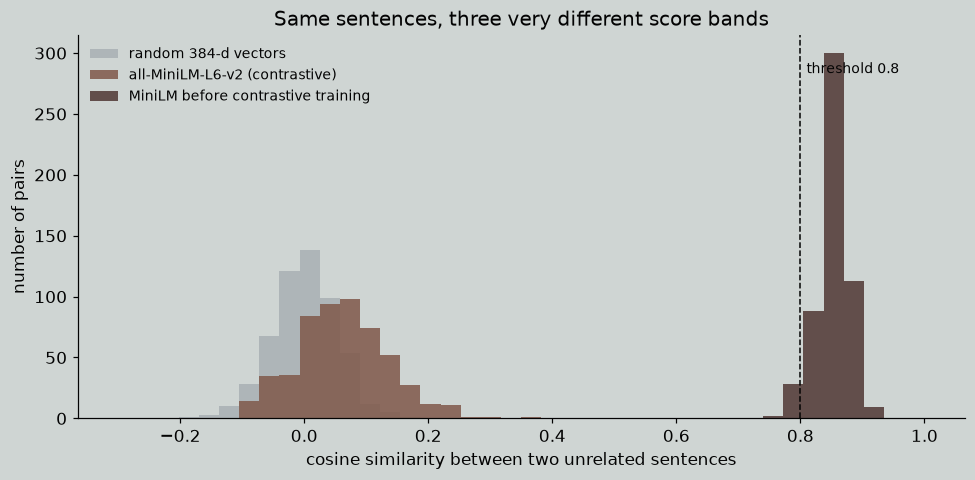

In [9]:
pool = {
    "invoices": ["The supplier still hasn't paid the March invoice.", "Invoice INV-2041 is now 60 days overdue.",
                 "Please chase the client about the unpaid bill.", "Late payments are hurting our cash flow.",
                 "Send the customer a final payment reminder.", "The credit note was issued last week."],
    "football": ["Barcelona scored twice in the second half.", "The goalkeeper saved a penalty in extra time.",
                 "The striker was sent off after a reckless tackle.", "Fans filled the stadium for the derby.",
                 "The coach changed the formation at half time.", "The league title was decided on the last day."],
    "recipes":  ["Fry the onions slowly until they turn golden.", "Add a pinch of saffron to the paella rice.",
                 "Beat the eggs and fold in the potatoes.", "Let the dough rest for an hour before baking.",
                 "Season the soup with salt and black pepper.", "Grill the peppers until the skin blisters."],
    "space":    ["The probe entered orbit around Jupiter.", "Saturn's rings are made mostly of ice.",
                 "The telescope captured light from a distant galaxy.", "Astronauts docked with the space station.",
                 "A comet passed close to the Sun.", "The rover drilled into Martian rock."],
    "music":    ["She tuned the guitar before the gig.", "The orchestra rehearsed the second movement.",
                 "The drummer kept a steady tempo.", "Their new album drops on Friday.",
                 "He practised scales on the piano every morning.", "The synth line repeats under the chorus."],
    "weather":  ["Heavy rain is expected across Glasgow tonight.", "The heatwave broke records in Seville.",
                 "Fog delayed flights at the airport.", "Snow closed the mountain pass.",
                 "A cold front will move in from the west.", "Strong winds brought down several trees."],
}
texts, labels = [], []
for t, ss in pool.items():
    texts += ss; labels += [t] * len(ss)
labels = np.array(labels)

base = SentenceTransformer("nreimers/MiniLM-L6-H384-uncased", device="cpu")   # same network, before contrastive training

def unrelated_cosines(X):
    C = cosine_similarity(X)
    i, j = np.triu_indices(len(X), k=1)
    keep = labels[i] != labels[j]
    return C[i, j][keep]

rng = np.random.default_rng(SEED)
results = {
    "random 384-d vectors": unrelated_cosines(rng.standard_normal((len(texts), 384))),
    "all-MiniLM-L6-v2 (contrastive)": unrelated_cosines(model.encode(texts)),
    "MiniLM before contrastive training": unrelated_cosines(base.encode(texts)),
}

print(f"{len(results['random 384-d vectors'])} unrelated pairs\n")
print(f"{'':<36}{'mean':>7}{'5th pct':>9}{'95th pct':>10}{'share > 0.8':>13}")
for name, c in results.items():
    print(f"{name:<36}{c.mean():7.3f}{np.percentile(c, 5):9.3f}{np.percentile(c, 95):10.3f}{(c > 0.8).mean():13.1%}")

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, c), col in zip(results.items(), [LIGHT_GREY, BROWN, DARK_BROWN]):
    ax.hist(c, bins=40, range=(-0.3, 1), alpha=0.85, color=col, label=name)
ax.axvline(0.8, color=TEXT, ls="--", lw=1)
ax.text(0.81, ax.get_ylim()[1] * 0.9, "threshold 0.8", fontsize=9)
ax.set_xlabel("cosine similarity between two unrelated sentences")
ax.set_ylabel("number of pairs")
ax.set_title("Same sentences, three very different score bands")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**What you're seeing:** this is the plot I'd put on the wall of every RAG team. Random vectors centre on 0, as they should in 384 dimensions. all-MiniLM-L6-v2 sits just above that (mean 0.06) and none of these unrelated pairs gets anywhere near 0.8. The same network before contrastive training puts unrelated pairs at 0.85 on average, and 96% of them clear the 0.8 threshold. Same sentences, same architecture, and the meaning of "0.8" flips completely. So when someone tells you their retrieval threshold, ask "for which model?", and calibrate your own on pairs you know are unrelated.

## Step 9 · Where it breaks: cosine goes both ways

Cosine is symmetric, always: $\cos(u, v) = \cos(v, u)$, because the dot product doesn't care about order. A lot of meaning *does* care about order. "A dog is an animal" is true and "an animal is a dog" is not. Hierarchies, "is a kind of", "is part of" and "was caused by" all run one way, and a symmetric score has no way to tell you which way.

In [10]:
dog, animal = model.encode(["dog", "animal"], normalize_embeddings=True)
print("cos(dog, animal) =", round(float(dog @ animal), 4))
print("cos(animal, dog) =", round(float(animal @ dog), 4))

a, b = model.encode(["A dog is an animal.", "An animal is a dog."], normalize_embeddings=True)
print("\ncos('A dog is an animal.', 'An animal is a dog.') =", round(float(a @ b), 4))

cos(dog, animal) = 0.8156
cos(animal, dog) = 0.8156

cos('A dog is an animal.', 'An animal is a dog.') = 0.9926


**What you're seeing:** the first two numbers are identical, as they have to be. The third one is the fun one. "A dog is an animal" and "An animal is a dog" score 0.99, so they're almost the same vector, even though one is true and the other is false. Word order barely moves a sentence embedding, and a symmetric score has nowhere to store which way a relationship runs. Hierarchies need a different geometry, and that's where notebook 02 picks up.

There's a second, sneakier problem. Steck, Ekanadham & Kallus (WWW '24 Companion) point out that the cosine between learned embeddings can be **arbitrary**. The reason is a symmetry in training.

Take the classic recommender setup. Every user gets a vector $u$, every item gets a vector $v$, and the model is trained so that the dot product $u \cdot v$ predicts how much the user likes the item. Training only ever sees those dot products. Now pick any diagonal matrix $D$ (it just stretches each dimension by its own amount) and replace

$$u \to D^{-1} u, \qquad v \to D\, v .$$

Every dot product stays exactly the same, because $(D^{-1}u) \cdot (D v) = u \cdot v$. So training has no reason to prefer one version over the other, and both fit the data perfectly well. But the cosine between two *items* does change, because stretching dimensions changes angles. Which version you end up with depends on things like initialisation and regularisation, and the item-to-item similarities you'd show a user depend on that accident.

Here's the smallest example I know, the one from the talk. A film recommender predicts a rating as user · film. Take two films and one user, then multiply every film's first number by 3 and divide every user's first number by 3.

In [11]:
films = np.array([[1, 1], [1, -1]])     # film A, film B
users = np.array([[2, 3]])
D = np.diag([3, 1])                     # films' 1st number x3, users' 1st number /3
films2, users2 = films @ D, users @ np.linalg.inv(D)

print("ratings before:", users @ films.T)
print("ratings after: ", users2 @ films2.T)
print("cos(A, B) before:", round(cosine_similarity(films)[0, 1], 3))
print("cos(A, B) after: ", round(cosine_similarity(films2)[0, 1], 3))

ratings before: [[ 5 -1]]
ratings after:  [[ 5. -1.]]
cos(A, B) before: 0.0
cos(A, B) after:  0.8


**What you're seeing:** both sets predict exactly the same ratings, 5 and −1, so training has no reason to prefer one over the other. But the cosine between the two films jumps from 0.0 (unrelated) to 0.8 (very similar). Nothing about the films changed, only a rescaling that the training objective can't see.

Two films is a toy, so let's watch it happen at a bigger scale with random vectors.

In [12]:
rng = np.random.default_rng(SEED)
n_users, n_items, dim = 50, 20, 8
U = rng.standard_normal((n_users, dim))
V = rng.standard_normal((n_items, dim))

d = rng.uniform(0.2, 5.0, size=dim)            # a random stretch for each dimension
U2, V2 = U / d, V * d                           # u -> D^-1 u,  v -> D v

print("Largest change in any user-item dot product:", f"{np.abs(U @ V.T - U2 @ V2.T).max():.1e}")

C1, C2 = cosine_similarity(V), cosine_similarity(V2)
np.fill_diagonal(C1, -np.inf); np.fill_diagonal(C2, -np.inf)
nn1, nn2 = C1.argmax(axis=1), C2.argmax(axis=1)

print(f"\ncos(item 0, item 1) before: {C1[0, 1]:.3f}   after: {C2[0, 1]:.3f}")
print(f"Items whose most similar item changed: {(nn1 != nn2).sum()} out of {n_items}")

Largest change in any user-item dot product: 1.8e-15

cos(item 0, item 1) before: 0.108   after: 0.020
Items whose most similar item changed: 11 out of 20


**What you're seeing:** the dot products, which are all training ever sees, change by about $10^{-15}$, which is floating-point noise. Meanwhile the cosine between item 0 and item 1 drops from 0.11 to 0.02, and 11 of the 20 items get a different "most similar item". Both versions fit the data equally well. If you serve "customers who liked this also liked..." from item cosines, more than half of those recommendations depend on a choice training never made.

## Step 10 · Takeaway

Cosine similarity in flat space bakes in three assumptions (direction is all that matters, every relationship runs both ways, and the scale of each dimension means something), and none of them comes for free. Check them against your own data before you trust a score, then open notebook 02, where we swap flat space for a curved one and see what that does for a hierarchy.